In [41]:
import pandas as pd
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt

In [42]:
alimentacion = pd.read_csv("./dataframes/alimentacion_df_limpio_DEs.csv", sep=',')

C:\Users\alexa\AppData\Local\Temp\ipykernel_7468\897800558.py:1: DtypeWarning: Columns (8: categories) have mixed types. Specify dtype option on import or set low_memory=False.
  alimentacion = pd.read_csv("./dataframes/alimentacion_df_limpio_DEs.csv", sep=',')


In [43]:
# Explicación de la expresión regular:
# ^(?:.*?en:)? -> Ignora de forma opcional todo hasta el "en:" si existe.
# ([^,]+)       -> COLUMNA 1: Captura todo lo que NO sea una coma (hasta encontrar la primera coma).
# ,(.*)$        -> COLUMNA 2: Salta la coma y captura todo el resto del texto hasta el final.
patron = r'^(?:.*?en:)?([^,]+),(.*)$'
alimentacion[['categoria_principal', 'categorias_secundarias']] = alimentacion['categories_en'].str.extract(patron)

In [44]:
alimentacion.columns

Index(['created_datetime', 'last_modified_datetime', 'product_name',
       'quantity', 'packaging', 'packaging_tags', 'packaging_en', 'brands',
       'categories', 'categories_tags', 'categories_en', 'origins_en',
       'manufacturing_places_tags', 'labels', 'labels_tags', 'labels_en',
       'stores', 'countries_en', 'ingredients_text', 'ingredients_tags',
       'ingredients_analysis_tags', 'allergens_en', 'additives_tags',
       'additives_en', 'nutriscore_score', 'nutriscore_grade', 'nova_group',
       'food_groups', 'food_groups_tags', 'food_groups_en', 'brand_owner',
       'environmental_score_score', 'environmental_score_grade',
       'posibles_DEs_en_ingredientes', 'posibles_DEs_en_aditivos',
       'posibles_DEs_totales', 'cantidad_posibles_DEs', 'tiene_algun_DE',
       'categoria_principal', 'categorias_secundarias'],
      dtype='str')

In [45]:
alimentacion["ingredients_text"]

0         XYLITOL, GUM BASE, ISOMALT, GUM ARABIC, SORBIT...
1         _Seitán_ 83% (agua, gluten de _trigo_, harina ...
2         _Cheddar_ (51%), eau, _fromage_ (9%), _lait_ é...
3                           Vinagre, chile rojo (19%), sal.
4                                                       NaN
                                ...                        
331160                                                  NaN
331161                                                  NaN
331162                                                  NaN
331163                                                  NaN
331164                                                  NaN
Name: ingredients_text, Length: 331165, dtype: str

In [46]:
alimentacion.head(2)

,created_datetime,last_modified_datetime,product_name,quantity,packaging,packaging_tags,packaging_en,brands,categories,categories_tags,...,brand_owner,environmental_score_score,environmental_score_grade,posibles_DEs_en_ingredientes,posibles_DEs_en_aditivos,posibles_DEs_totales,cantidad_posibles_DEs,tiene_algun_DE,categoria_principal,categorias_secundarias
0,2018-08-20T08:22:17Z,2026-08-15T09:58:51Z,gum cool watermelon,56 Pieces,NaN,NaN,NaN,Tic Tac,NaN,"en:snacks,en:sweet-snacks,en:confectioneries,e...",...,"Ferrero U.S.A., Incorporated",NaN,unknown,[],"['acesulfamo k', 'butilhidroxitolueno (bht)', ...","['sucralosa', 'acesulfamo k', 'butilhidroxitol...",4,True,chewing-gum,Sugar-free chewing gum
1,2012-06-28T19:53:01Z,2026-03-27T13:53:35Z,Seitán en lonchas,300 g,"Bolsa de plástico,Refrigerado,Pasteurizado,Env...","bolsa-de-plastico,refrigerado,pasteurizado,env...","bolsa-de-plastico,refrigerado,pasteurizado,env...",Soria Natural,NaN,"en:plant-based-foods-and-beverages,en:plant-ba...",...,NaN,90.0,a-plus,[],[],[],0,False,Plant-based foods and beverages,"Plant-based foods,Cereals and potatoes,Cereals..."


In [47]:
alimentacion["environmental_score_grade"].value_counts()

environmental_score_grade
unknown           244393
b                  20226
d                  15560
e                  14743
c                  11544
a                  10460
f                   8128
a-plus              3306
not-applicable      2805
Name: count, dtype: int64

In [48]:
eco_df = alimentacion[alimentacion["environmental_score_grade"].isin(["a-plus", "a", "b", "c", "d", "e", "f"])]

In [49]:
eco_df.info()

<class 'pandas.DataFrame'>
Index: 83967 entries, 1 to 331087
Data columns (total 40 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   created_datetime              83967 non-null  str    
 1   last_modified_datetime        83967 non-null  str    
 2   product_name                  83967 non-null  str    
 3   quantity                      36387 non-null  str    
 4   packaging                     13271 non-null  str    
 5   packaging_tags                13268 non-null  str    
 6   packaging_en                  13268 non-null  str    
 7   brands                        83967 non-null  str    
 8   categories                    56436 non-null  str    
 9   categories_tags               83967 non-null  str    
 10  categories_en                 83967 non-null  str    
 11  origins_en                    6726 non-null   str    
 12  manufacturing_places_tags     8001 non-null   str    
 13  labels          

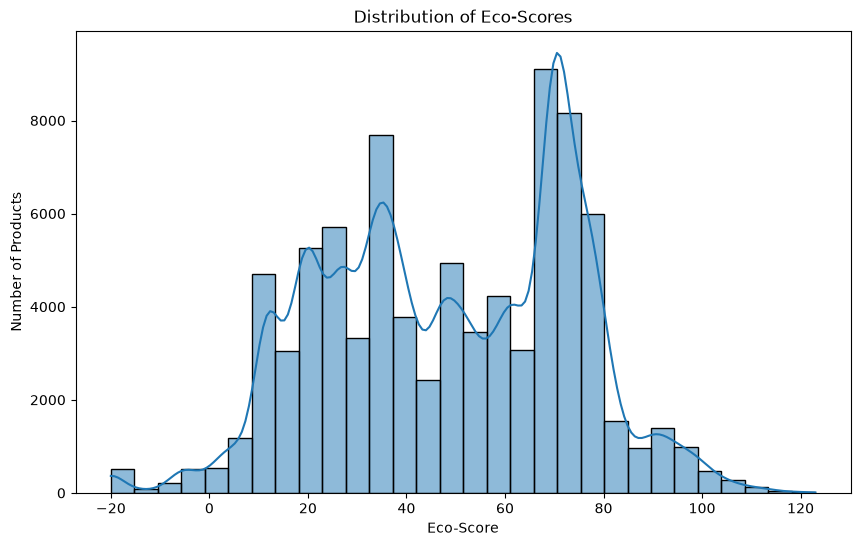

In [50]:
plt.figure(figsize=(10, 6))
sns.histplot(data=eco_df[eco_df['environmental_score_score'] != -1], x='environmental_score_score', bins=30, kde = True)
plt.title('Distribution of Eco-Scores')
plt.xlabel('Eco-Score')
plt.ylabel('Number of Products')
plt.show()

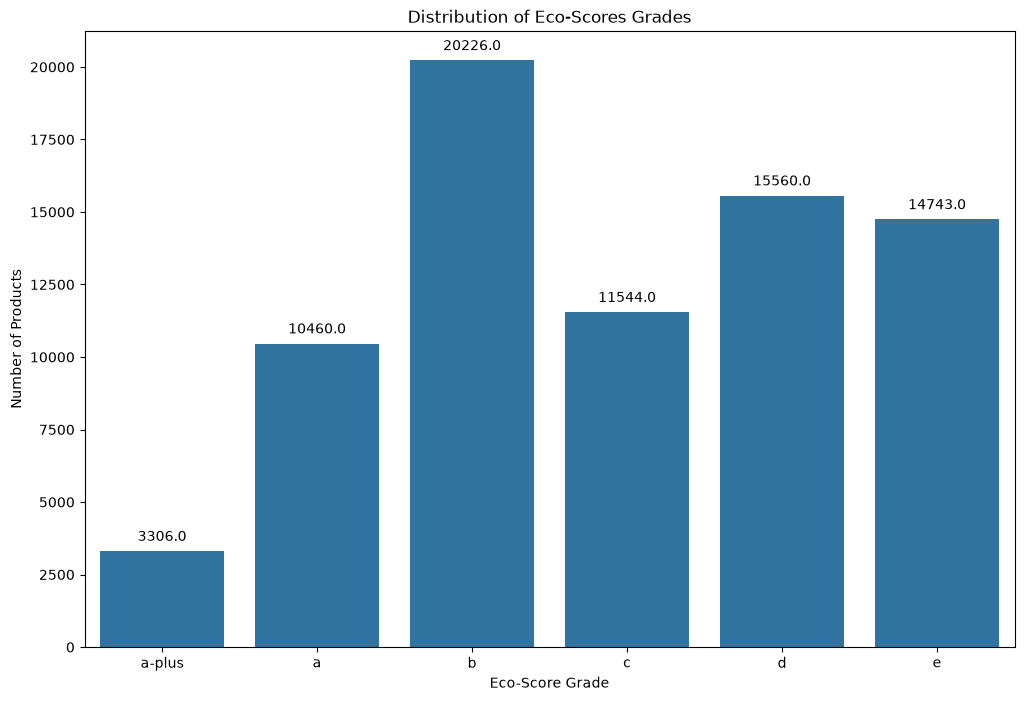

In [52]:
plt.figure(figsize=(12, 8))
eco_score_colors = ['darkgreen', 'green', 'lightgreen', 'yellow', 'orange', 'red']  # Corresponding to ['a', 'b', 'c', 'd', 'e']
ax = sns.countplot(x='environmental_score_grade', data=eco_df, order=['a-plus', 'a', 'b', 'c', 'd', 'e'])
plt.title('Distribution of Eco-Scores Grades')
plt.xlabel('Eco-Score Grade')
plt.ylabel('Number of Products');

# Add annotations for each bar
for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 10), textcoords='offset points');

plt.show();

In [53]:
alimentacion["categoria_principal"].value_counts()

categoria_principal
Plant-based foods and beverages         41359
Snacks                                  17948
Dairies                                 12186
Meats and their products                 9977
Beverages and beverages preparations     7786
                                        ...  
bolognese-soße                              1
food supplement                             1
electronics                                 1
Non-food-products                           1
Biscuits                                    1
Name: count, Length: 581, dtype: int64

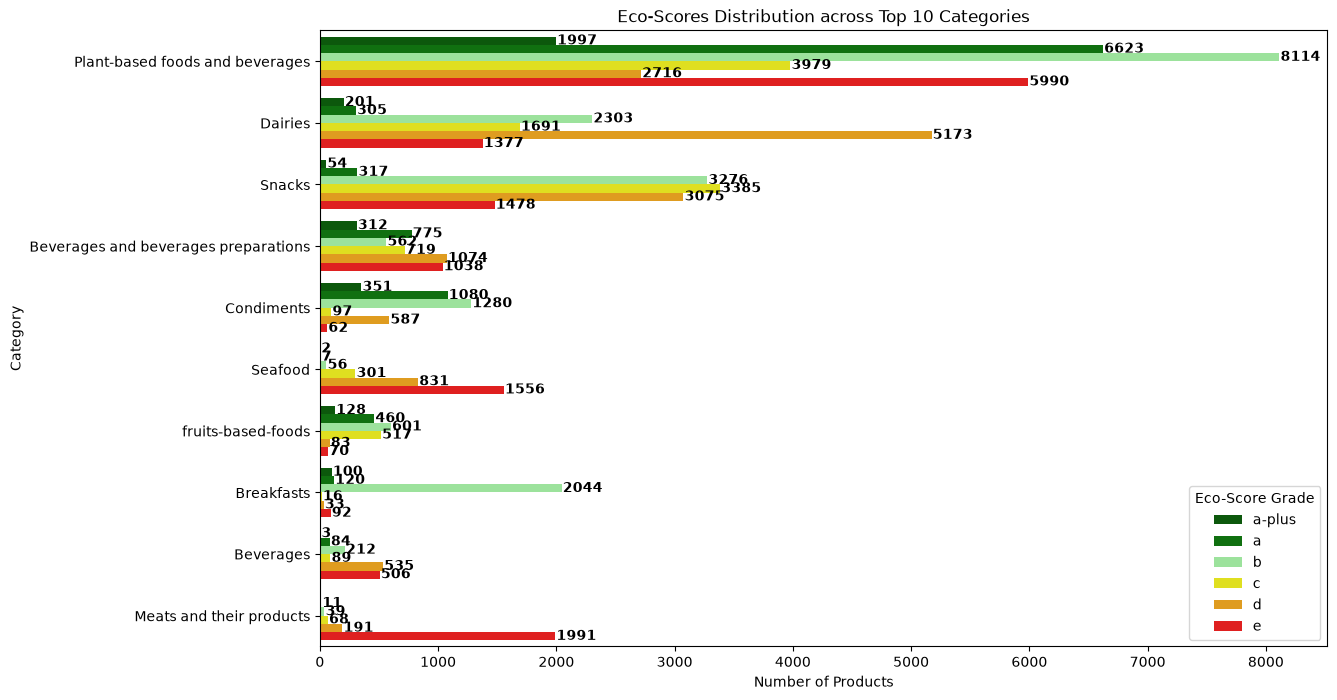

In [54]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

eco_score_colors = {
    'a-plus': 'darkgreen',
    'a': 'green',
    'b': 'lightgreen',
    'c': 'yellow',
    'd': 'orange',
    'e': 'red',
}

top_categories = (
    eco_df[eco_df['environmental_score_score'] != -1]['categoria_principal']
    .value_counts()
    .head(10)
    .index
)

# Filtrar los datos necesarios
filtered_df = eco_df[
    (eco_df['environmental_score_score'] != -1)
    & (eco_df['categoria_principal'].isin(top_categories))
]

plt.figure(figsize=(13, 8))
ax = sns.countplot(
    y='categoria_principal',
    hue='environmental_score_grade',
    data=filtered_df,
    hue_order=['a-plus', 'a', 'b', 'c', 'd', 'e'],
    palette=eco_score_colors,
)

# Annotate each bar with its count (con protección contra valores NaN)
for p in ax.patches:
  width = p.get_width()
  if pd.isna(width) or width == 0:
    continue
  height = p.get_height()
  x, y = p.get_x() + width, p.get_y() + height / 2
  ax.annotate(
      f'{int(width)}',
      (x + 10, y),
      ha='left',
      va='center',
      color='black',
      weight='bold',
      fontsize=10,
  )

plt.title('Eco-Scores Distribution across Top 10 Categories')
plt.xlabel('Number of Products')
plt.ylabel('Category')
plt.legend(title='Eco-Score Grade')
plt.show()

In [55]:
eco_df.groupby("environmental_score_grade")["cantidad_posibles_DEs"].sum()

environmental_score_grade
a          578
a-plus     128
b         1203
c          516
d          674
e          779
f          543
Name: cantidad_posibles_DEs, dtype: int64

In [56]:
eco_df["categories_en"]

1         Plant-based foods and beverages,Plant-based fo...
2         Dairies,Fermented foods,Fermented milk product...
7              Sweeteners,Syrups,Simple syrups,Agave syrups
9         Plant-based foods and beverages,Plant-based fo...
10        Snacks,Sweet snacks,Biscuits and cakes,Biscuit...
                                ...                        
330959    Plant-based foods and beverages,Plant-based fo...
330968    Plant-based foods and beverages,Plant-based fo...
330990    Beverages and beverages preparations,Beverages...
331010    Beverages and beverages preparations,Plant-bas...
331087    Beverages and beverages preparations,Beverages...
Name: categories_en, Length: 83967, dtype: str

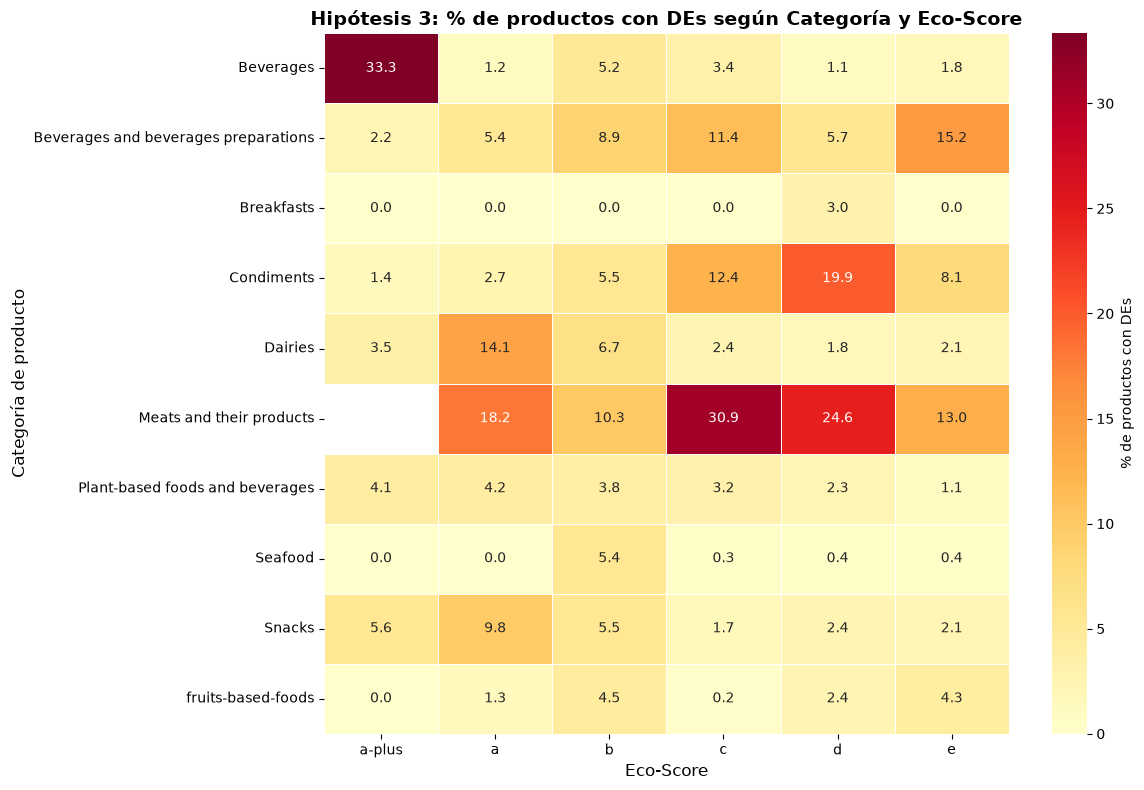

In [57]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Filtramos solo productos con Eco-Score válido
df_eco = alimentacion[
    alimentacion['environmental_score_grade'].isin(['a-plus', 'a', 'b', 'c', 'd', 'e'])
].copy()

# 3. Calculamos el % de productos con DEs por cada combinación Categoría × Eco-Score
# (Usamos las 10 categorías principales para que no quede saturado)
top_categorias = df_eco['categoria_principal'].value_counts().head(10).index
df_eco_top = df_eco[df_eco['categoria_principal'].isin(top_categorias)]

tabla_DE = df_eco_top.groupby(['categoria_principal', 'environmental_score_grade'])['tiene_algun_DE'].mean() * 100

# 4. Reorganizamos en formato matriz
tabla_matriz = tabla_DE.unstack(level='environmental_score_grade')
tabla_matriz = tabla_matriz.reindex(['a-plus', 'a', 'b', 'c', 'd', 'e'], axis=1)

# 5. Dibujamos el heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    tabla_matriz,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    cbar_kws={'label': '% de productos con DEs'},
    linewidths=0.5,
    linecolor='white'
)

plt.title('Hipótesis 3: % de productos con DEs según Categoría y Eco-Score', 
          fontsize=14, fontweight='bold')
plt.xlabel('Eco-Score', fontsize=12)
plt.ylabel('Categoría de producto', fontsize=12)
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

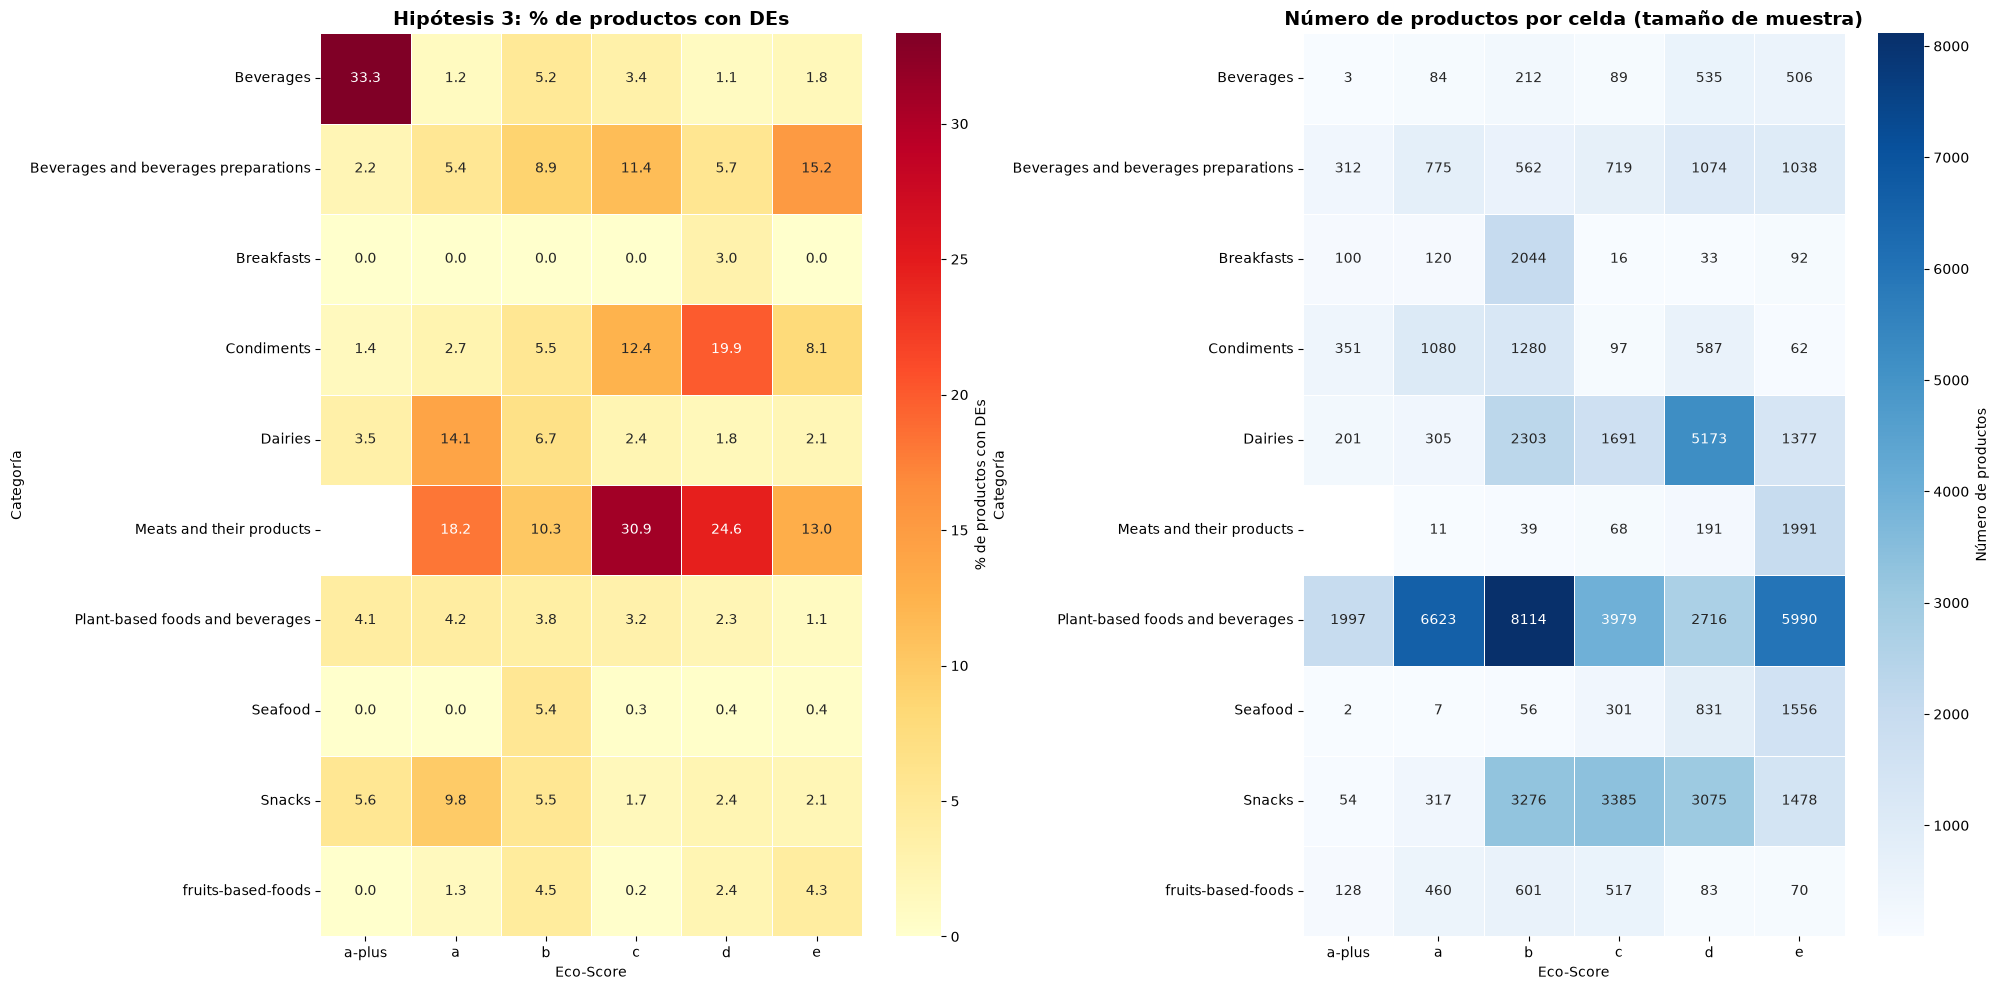

In [58]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Filtrar productos con Eco-Score válido
df_eco = alimentacion[
    alimentacion['environmental_score_grade'].isin(['a-plus', 'a', 'b', 'c', 'd', 'e'])
].copy()

# 3. Usar las 10 categorías principales
top_categorias = df_eco['categoria_principal'].value_counts().head(10).index
df_eco_top = df_eco[df_eco['categoria_principal'].isin(top_categorias)]

# 4. Calcular % de DEs por celda
tabla_DE = df_eco_top.groupby(['categoria_principal', 'environmental_score_grade'])['tiene_algun_DE'].mean() * 100
tabla_matriz_DE = tabla_DE.unstack(level='environmental_score_grade')
tabla_matriz_DE = tabla_matriz_DE.reindex(['a-plus', 'a', 'b', 'c', 'd', 'e'], axis=1)

# 5. Calcular NÚMERO de productos por celda (esto es lo nuevo)
tabla_n = df_eco_top.groupby(['categoria_principal', 'environmental_score_grade']).size()
tabla_matriz_n = tabla_n.unstack(level='environmental_score_grade')
tabla_matriz_n = tabla_matriz_n.reindex(['a-plus', 'a', 'b', 'c', 'd', 'e'], axis=1)

# 6. Dibujar ambos heatmaps lado a lado
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

# Heatmap 1: % de DEs
sns.heatmap(
    tabla_matriz_DE,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    cbar_kws={'label': '% de productos con DEs'},
    linewidths=0.5,
    linecolor='white',
    ax=axes[0]
)
axes[0].set_title('Hipótesis 3: % de productos con DEs', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Eco-Score')
axes[0].set_ylabel('Categoría')

# Heatmap 2: Número de productos
sns.heatmap(
    tabla_matriz_n,
    annot=True,
    fmt='.0f',
    cmap='Blues',
    cbar_kws={'label': 'Número de productos'},
    linewidths=0.5,
    linecolor='white',
    ax=axes[1]
)
axes[1].set_title('Número de productos por celda (tamaño de muestra)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Eco-Score')
axes[1].set_ylabel('Categoría')

plt.tight_layout()
plt.show()

<Figure size 1400x700 with 0 Axes>

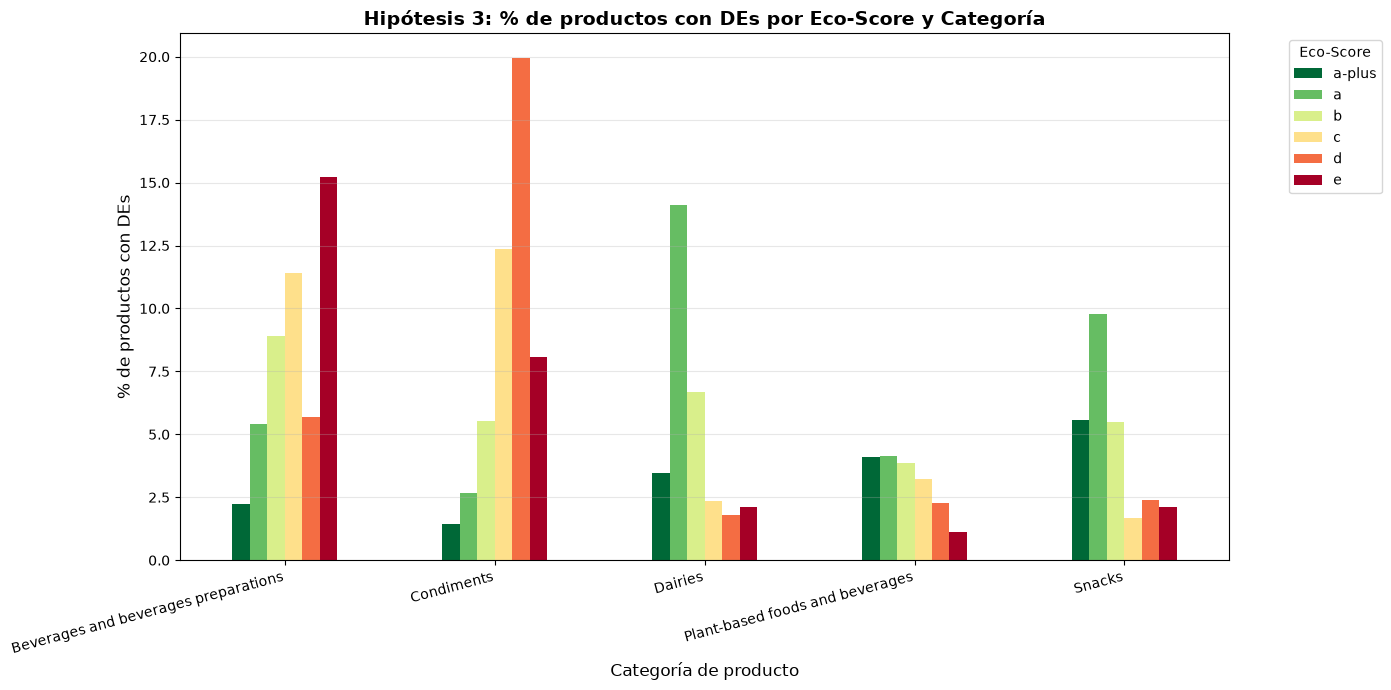

In [60]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Filtrar y preparar
df_eco = alimentacion[
    alimentacion['environmental_score_grade'].isin(['a-plus', 'a', 'b', 'c', 'd', 'e'])
].copy()

# 2. Seleccionar las 5 categorías con más productos (para no saturar)
top_5_cats = df_eco['categoria_principal'].value_counts().head(5).index
df_eco_top = df_eco[df_eco['categoria_principal'].isin(top_5_cats)]

# 3. Calcular % de DEs por combinación
tabla_DE = df_eco_top.groupby(['categoria_principal', 'environmental_score_grade'])['tiene_algun_DE'].mean() * 100
tabla_matriz = tabla_DE.unstack(level='environmental_score_grade')
tabla_matriz = tabla_matriz.reindex(['a-plus', 'a', 'b', 'c', 'd', 'e'], axis=1)

# 4. Gráfico de barras agrupadas
plt.figure(figsize=(14, 7))
tabla_matriz.plot(kind='bar', figsize=(14, 7), colormap='RdYlGn_r')

plt.title('Hipótesis 3: % de productos con DEs por Eco-Score y Categoría', 
          fontsize=14, fontweight='bold')
plt.xlabel('Categoría de producto', fontsize=12)
plt.ylabel('% de productos con DEs', fontsize=12)
plt.legend(title='Eco-Score', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=15, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

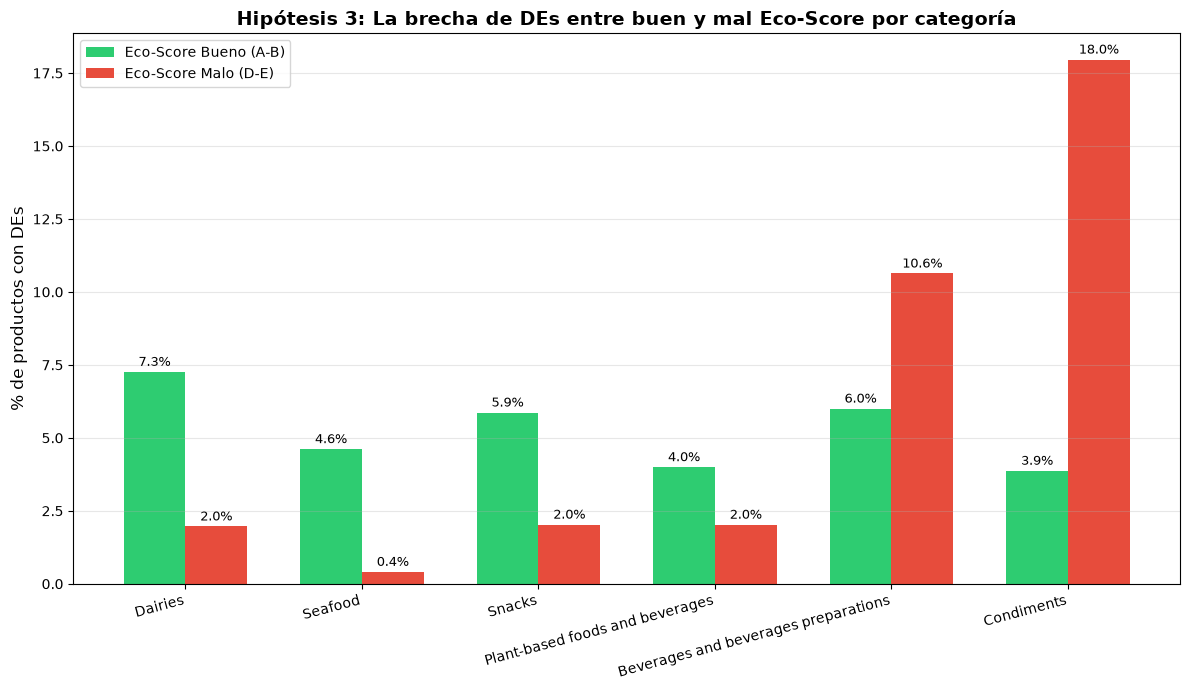


--- % de DEs por categoría y grupo de Eco-Score ---
grupo_eco                             Bueno (A-B)  Malo (D-E)  brecha
categoria_principal                                                  
Dairies                                      7.26        1.97   -5.30
Seafood                                      4.62        0.41   -4.21
Snacks                                       5.87        2.03   -3.84
Plant-based foods and beverages              4.00        2.03   -1.97
Beverages and beverages preparations         6.00       10.63    4.63
Condiments                                   3.87       17.96   14.09


In [61]:
# ESTE GRÁFICO PARECE EL QUE MEJOR SE VISUALIZA

import pandas as pd
import matplotlib.pyplot as plt

# 1. Preparar datos
df_eco = alimentacion[
    alimentacion['environmental_score_grade'].isin(['a-plus', 'a', 'b', 'c', 'd', 'e'])
].copy()

# 2. Crear grupo "Buen Eco" vs "Mal Eco"
df_eco['grupo_eco'] = df_eco['environmental_score_grade'].apply(
    lambda x: 'Bueno (A-B)' if x in ['a-plus', 'a', 'b'] else 'Malo (D-E)'
)
# Excluimos 'c' para hacer la comparación más clara

df_comparacion = df_eco[df_eco['grupo_eco'].isin(['Bueno (A-B)', 'Malo (D-E)'])]

# 3. Calcular % de DEs por categoría y grupo
top_6_cats = df_comparacion['categoria_principal'].value_counts().head(6).index
df_top = df_comparacion[df_comparacion['categoria_principal'].isin(top_6_cats)]

resultado = df_top.groupby(['categoria_principal', 'grupo_eco'])['tiene_algun_DE'].mean() * 100
resultado_matriz = resultado.unstack(level='grupo_eco')

# 4. Calcular la "brecha" (diferencia entre malo y bueno)
resultado_matriz['brecha'] = resultado_matriz['Malo (D-E)'] - resultado_matriz['Bueno (A-B)']
resultado_matriz = resultado_matriz.sort_values('brecha', ascending=True)

# 5. Gráfico de barras comparativo
fig, ax = plt.subplots(figsize=(12, 7))
x = range(len(resultado_matriz))
width = 0.35

barras_bueno = ax.bar([i - width/2 for i in x], resultado_matriz['Bueno (A-B)'], 
                      width, label='Eco-Score Bueno (A-B)', color='#2ecc71')
barras_malo = ax.bar([i + width/2 for i in x], resultado_matriz['Malo (D-E)'], 
                     width, label='Eco-Score Malo (D-E)', color='#e74c3c')

ax.set_xticks(x)
ax.set_xticklabels(resultado_matriz.index, rotation=15, ha='right')
ax.set_ylabel('% de productos con DEs', fontsize=12)
ax.set_title('Hipótesis 3: La brecha de DEs entre buen y mal Eco-Score por categoría', 
             fontsize=14, fontweight='bold')
ax.legend()
ax.grid(axis='y', alpha=0.3)

# Añadir etiquetas con los valores
for barra in barras_bueno:
    altura = barra.get_height()
    ax.text(barra.get_x() + barra.get_width()/2, altura + 0.1, 
            f'{altura:.1f}%', ha='center', va='bottom', fontsize=9)
for barra in barras_malo:
    altura = barra.get_height()
    ax.text(barra.get_x() + barra.get_width()/2, altura + 0.1, 
            f'{altura:.1f}%', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

# 6. Imprimir la tabla para que veas los números
print("\n--- % de DEs por categoría y grupo de Eco-Score ---")
print(resultado_matriz[['Bueno (A-B)', 'Malo (D-E)', 'brecha']].round(2))

In [62]:
alimentacion.to_csv("./dataframes/alimentacion_df_limpio_DEs_categorias.csv", sep=',', index=False, encoding='utf-8')

In [63]:
import pandas as pd
from scipy.stats import chi2_contingency

# Creamos una tabla de contingencia entre el Eco-Score (o tu versión agrupada A-B vs D-E) y la presencia de DEs
contingency_table = pd.crosstab(alimentacion['environmental_score_grade'], alimentacion['tiene_algun_DE'])

# Ejecutamos el test de Chi-cuadrado
chi2, p_val, dof, expected = chi2_contingency(contingency_table)

print(f"Estadístico Chi2: {chi2:.4f}")
print(f"P-valor: {p_val:.4e}")

Estadístico Chi2: 4930.2838
P-valor: 0.0000e+00


In [74]:
import pandas as pd
from scipy.stats import chi2_contingency
import statsmodels.formula.api as smf

# 1. Función para agrupar el Eco-Score (incluyendo 'a-plus'/'a+' en el grupo A-B)
def agrupar_ecoscore(grade):
    if pd.isna(grade):
        return None
    g = str(grade).lower().strip()
    if g in ['a-plus', 'a', 'b']:
        return 'A-B (Bueno)'
    elif g == 'c':
        return 'C (Neutro)'
    elif g in ['d', 'e']:
        return 'D-E (Malo)'
    return None

# Aplicar la agrupación al DataFrame
alimentacion['eco_score_grupo'] = alimentacion['environmental_score_grade'].apply(agrupar_ecoscore)

# Filtrar registros válidos para el análisis
df_h2 = alimentacion.dropna(subset=['eco_score_grupo', 'tiene_algun_DE']).copy()

In [75]:
# ==========================================
# 2. TEST DE CHI-CUADRADO
# ==========================================
contingency_table = pd.crosstab(df_h2['eco_score_grupo'], df_h2['tiene_algun_DE'])
chi2, p_val, dof, expected = chi2_contingency(contingency_table)

print("--- 1. TEST DE CHI-CUADRADO ---")
print(f"Estadístico Chi2: {chi2:.4f}")
print(f"P-valor: {p_val:.4e}")
print("\nTabla de contingencia:")
print(contingency_table)
print("-" * 40)

--- 1. TEST DE CHI-CUADRADO ---
Estadístico Chi2: 18.0727
P-valor: 1.1901e-04

Tabla de contingencia:
tiene_algun_DE   False  True 
eco_score_grupo              
A-B (Bueno)      32576   1416
C (Neutro)       11162    382
D-E (Malo)       29153   1150
----------------------------------------


In [77]:
# ==========================================
# 3. REGRESIÓN LOGÍSTICA MULTIVARIANTE
# ==========================================

alimentacion['tiene_algun_DE_int'] = alimentacion['tiene_algun_DE'].astype(int)

# Controlamos por el grupo NOVA para ver el efecto neto del Eco-score
# Tomamos 'A-B (Bueno)' como categoría de referencia
formula = 'tiene_algun_DE_int ~ C(eco_score_grupo, Treatment(reference="A-B (Bueno)")) + C(nova_group)'

modelo = smf.logit(formula, data=df_h2).fit()

print("\n--- 2. REGRESIÓN LOGÍSTICA MULTIVARIANTE ---")
print(modelo.summary())

Optimization terminated successfully.
         Current function value: 0.108552
         Iterations 12

--- 2. REGRESIÓN LOGÍSTICA MULTIVARIANTE ---
                           Logit Regression Results                           
Dep. Variable:     tiene_algun_DE_int   No. Observations:                75839
Model:                          Logit   Df Residuals:                    75832
Method:                           MLE   Df Model:                            6
Date:               mi., 11 nov. 2026   Pseudo R-squ.:                  0.3395
Time:                        16:11:31   Log-Likelihood:                -8232.4
converged:                       True   LL-Null:                       -12464.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------

In [67]:
alimentacion.loc[alimentacion['categoria_principal'].str.contains("beverages", case=False), "categoria_principal"] = "Bebidas"

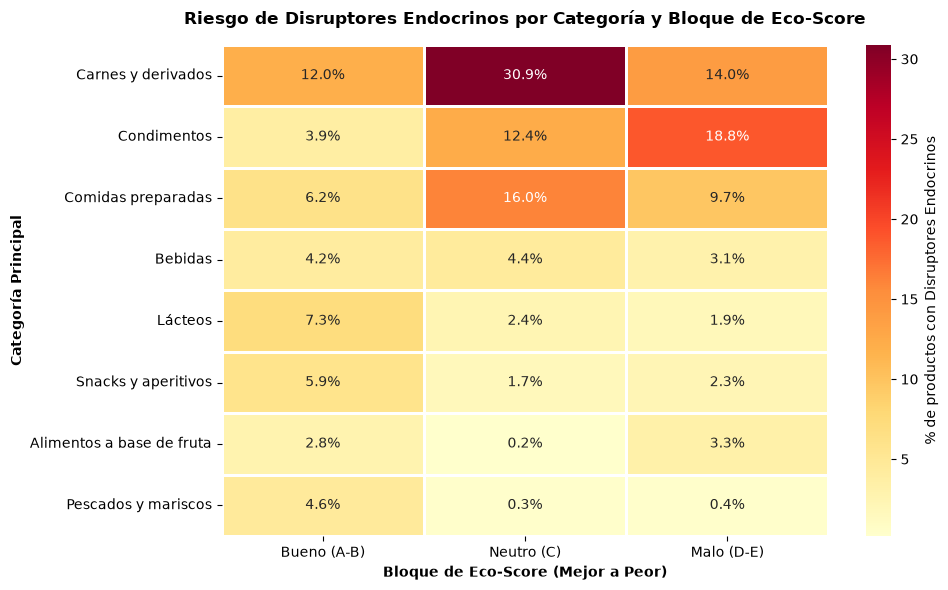

In [72]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Agrupación y orden lógico estricto para el Eje X
def agrupar_ecoscore(score):
    if score in ['a-plus', 'a', 'b']:
        return 'Bueno (A-B)'
    elif score == 'c':
        return 'Neutro (C)'
    elif score in ['d', 'e']:
        return 'Malo (D-E)'
    else:
        return np.nan

alimentacion['eco_grupo'] = alimentacion['environmental_score_grade'].apply(agrupar_ecoscore)

# Forzar el orden categórico lógico en el eje X
orden_eco = ['Bueno (A-B)', 'Neutro (C)', 'Malo (D-E)']
alimentacion['eco_grupo'] = pd.Categorical(alimentacion['eco_grupo'], categories=orden_eco, ordered=True)

# 2. Filtrar top 8 categorías principales
top_categorias = alimentacion['categoria_principal'].value_counts().nlargest(8).index
df_filtrado = alimentacion[alimentacion['categoria_principal'].isin(top_categorias)].copy()

# 3. Tablas cruzadas
df_pct = df_filtrado.pivot_table(
    index='categoria_principal', 
    columns='eco_grupo', 
    values='tiene_algun_DE_int', 
    aggfunc=lambda x: x.mean() * 100
)

df_n = df_filtrado.pivot_table(
    index='categoria_principal', 
    columns='eco_grupo', 
    values='tiene_algun_DE_int', 
    aggfunc='count'
)

# REORDENAR FILAS: Ordenar las categorías de mayor a menor porcentaje medio de disruptores
df_pct['media_riesgo'] = df_pct.mean(axis=1)
df_pct = df_pct.sort_values(by='media_riesgo', ascending=False).drop(columns='media_riesgo')
df_n = df_n.reindex(df_pct.index)

# 4. Diccionario de traducción de categorías al castellano
traducciones = {
    'Meats and their products': 'Carnes y derivados',
    'Condiments': 'Condimentos',
    'Meals': 'Comidas preparadas',
    'Beverages and beverages preparations': 'Bebidas',
    'Beverages': 'Bebidas',
    'Dairies': 'Lácteos',
    'Snacks': 'Snacks y aperitivos',
    'fruits-based-foods': 'Alimentos a base de fruta',
    'Plant-based foods and beverages': 'Alimentos de origen vegetal',
    'Seafood': 'Pescados y mariscos',
    'Cereals and potatoes': 'Cereales y patatas',
    'Breakfasts': 'Desayunos'
}

# Aplicar traducción a los índices de ambos DataFrames
df_pct = df_pct.rename(index=traducciones)
df_n = df_n.rename(index=traducciones)

# 5. Matriz de anotación (SOLO porcentaje, sin las "n")
annot_matrix = pd.DataFrame('', index=df_pct.index, columns=df_pct.columns)
for idx in df_pct.index:
    for col in df_pct.columns:
        val_pct = df_pct.loc[idx, col]
        val_n = df_n.loc[idx, col]
        if pd.isna(val_pct) or val_n == 0:
            annot_matrix.loc[idx, col] = "Sin datos"
        else:
            annot_matrix.loc[idx, col] = f"{val_pct:.1f}%"

# 6. Dibujar el mapa de calor optimizado
plt.figure(figsize=(10, 6))
sns.heatmap(
    df_pct, 
    annot=annot_matrix, 
    fmt="", 
    cmap="YlOrRd", 
    cbar_kws={'label': '% de productos con Disruptores Endocrinos'},
    linewidths=1, 
    linecolor='white'
)

plt.title('Riesgo de Disruptores Endocrinos por Categoría y Bloque de Eco-Score', 
          fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Bloque de Eco-Score (Mejor a Peor)', fontsize=10, fontweight='bold')
plt.ylabel('Categoría Principal', fontsize=10, fontweight='bold')

plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()